In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("beauty_preprocessed.csv")
customer_df = pd.read_csv("customer_features_preprocessed.csv")

df["Order Date"] = pd.to_datetime(df["Order Date"])

print("Transaction Dataset Shape:", df.shape)
print("Customer Dataset Shape:", customer_df.shape)

print("\nDate Range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

print("\nCustomer Activity Status:")
print(customer_df["Activity_Status"].value_counts())


Transaction Dataset Shape: (51290, 19)
Customer Dataset Shape: (17415, 9)

Date Range:
Start: 2020-01-01 00:00:00
End: 2023-12-31 00:00:00

Customer Activity Status:
Activity_Status
Inactive    9768
Active      7647
Name: count, dtype: int64


In [2]:

print("========== DATASET INFO ==========")
df.info()

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\n========== DUPLICATE ROWS ==========")
print("Transaction duplicates:", df.duplicated().sum())
print("Customer duplicates:", customer_df.duplicated().sum())

print("\n========== NUMERICAL SUMMARY ==========")
print(
    df[["Quantity", "Sales", "Discount", "Profit"]]
    .describe()
    .round(2)
)

print("\n========== CATEGORY COUNTS ==========")
print(df["Category"].value_counts())

print("\n========== MARKET COUNTS ==========")
print(df["Market"].value_counts())


========== DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Row ID             51290 non-null  int64         
 1   Order ID           51290 non-null  object        
 2   Order Date         51290 non-null  datetime64[ns]
 3   Customer ID        51290 non-null  object        
 4   Segment            51290 non-null  object        
 5   City               51290 non-null  object        
 6   State              51290 non-null  object        
 7   Country            51290 non-null  object        
 8   Country latitude   51290 non-null  float64       
 9   Country longitude  51290 non-null  float64       
 10  Region             51290 non-null  object        
 11  Market             51290 non-null  object        
 12  Subcategory        51290 non-null  object        
 13  Category           51290 n


===== Quantity =====
Mean: 5.42
Median: 4.0
Skewness: 1.47
Minimum: 1
Maximum: 20

===== Sales =====
Mean: 127.07
Median: 56.0
Skewness: 6.4
Minimum: 2
Maximum: 3940

===== Discount =====
Mean: 0.14
Median: 0.0
Skewness: 1.39
Minimum: 0.0
Maximum: 0.85

===== Profit =====
Mean: 20.77
Median: 7.2
Skewness: 3.95
Minimum: -1746.0
Maximum: 1820.0


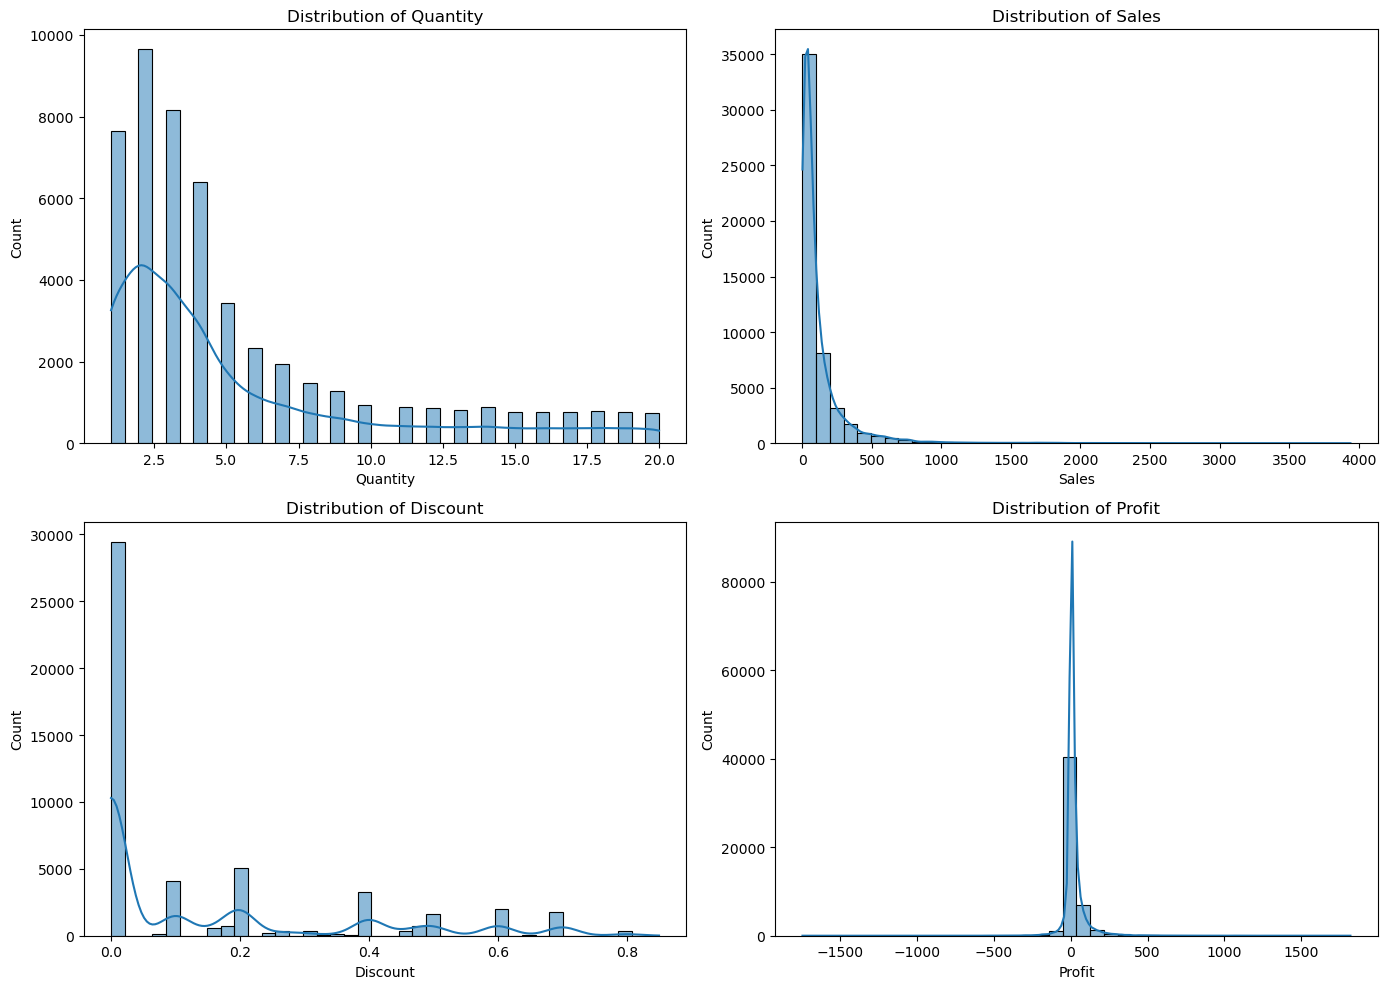

In [4]:



numerical_columns = ["Quantity", "Sales", "Discount", "Profit"]

for column in numerical_columns:
    print(f"\n===== {column} =====")
    print("Mean:", round(df[column].mean(), 2))
    print("Median:", round(df[column].median(), 2))
    print("Skewness:", round(df[column].skew(), 2))
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), numerical_columns):
    sns.histplot(data=df, x=column, bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()


First 12 Months:
Year_Month  Total_Sales  Total_Profit  Total_Orders
   2020-01        50460     10290.496           216
   2020-02        49815      8443.904           203
   2020-03        62773     13435.526           266
   2020-04        68707     11588.646           258
   2020-05        73493     14027.566           317
   2020-06       122286     21809.286           454
   2020-07        70993     10656.056           262
   2020-08       105207     20400.210           445
   2020-09       133633     25514.566           516
   2020-10       107889     17647.262           425
   2020-11       142135     26512.760           556
   2020-12       160970     26789.844           597

Yearly Summary:
 Year  Total_Sales  Total_Profit  Total_Orders
 2020      1148361     207116.12          4515
 2021      1405876     259696.96          5473
 2022      1770790     318671.89          6883
 2023      2192647     279928.68          8857


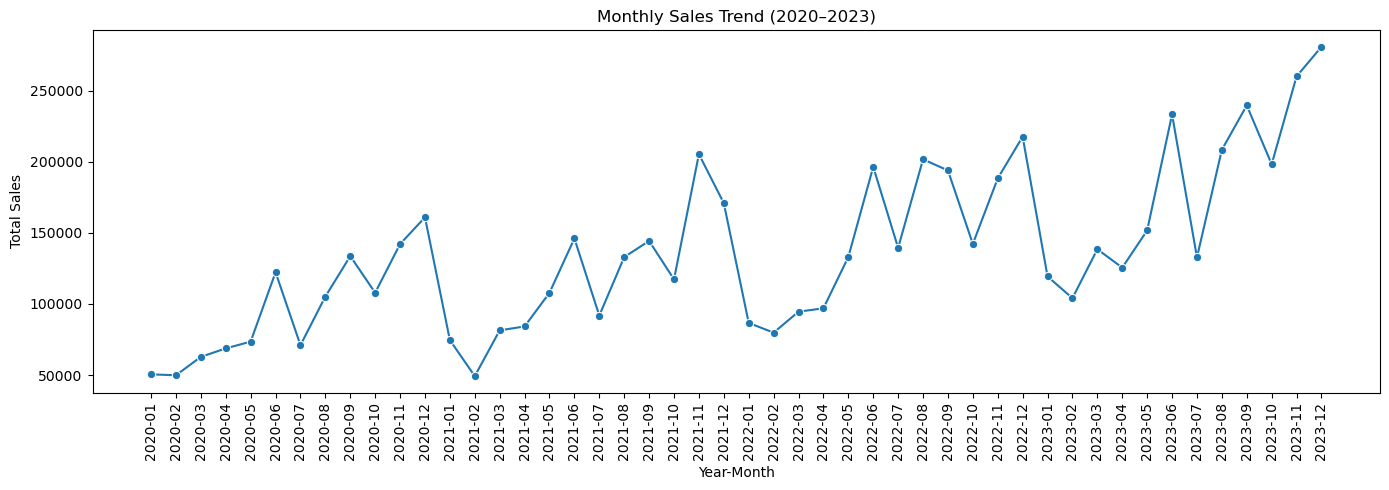

In [5]:

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)


monthly_trend = df.groupby("Year_Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

print("First 12 Months:")
print(monthly_trend.head(12).to_string(index=False))


yearly_trend = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

print("\nYearly Summary:")
print(yearly_trend.round(2).to_string(index=False))

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_trend,
    x="Year_Month",
    y="Total_Sales",
    marker="o"
)
plt.title("Monthly Sales Trend (2020–2023)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


===== CATEGORY PERFORMANCE =====
            Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  Profit_Margin_Pct
           body care      2682942     590907.78          113437         14855              22.02
home and accessories      1245643     -57187.64           52847          7986              -4.59
             make up      1121222     368998.18           48284          7613              32.91
           hair care      1022151       3677.23           43994          7067               0.36
           face care       445716     159018.10           19216          3199              35.68

===== MARKET PERFORMANCE =====
      Market  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  Profit_Margin_Pct
Asia Pacific      1831648     228742.59           77628          7080              12.49
      Europe      1487444     331644.70           64656          6013              22.30
        USCA      1372045     222770.12           57709          5203              16.

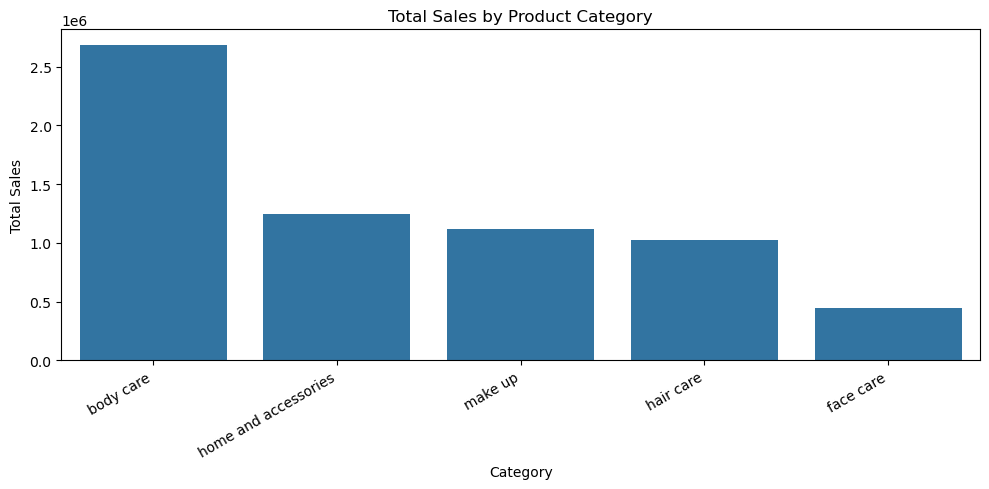

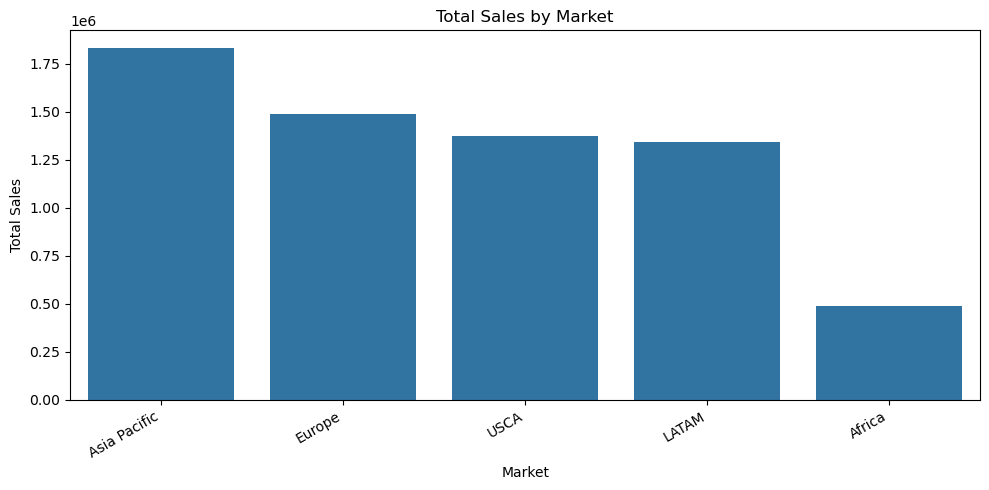

In [6]:

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

category_analysis["Profit_Margin_Pct"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

print("===== CATEGORY PERFORMANCE =====")
print(category_analysis.round(2).to_string(index=False))

market_analysis = df.groupby("Market").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

market_analysis["Profit_Margin_Pct"] = (
    market_analysis["Total_Profit"]
    / market_analysis["Total_Sales"] * 100
)

market_analysis = market_analysis.sort_values(
    "Total_Sales", ascending=False
)

print("\n===== MARKET PERFORMANCE =====")
print(market_analysis.round(2).to_string(index=False))


plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales"
)
plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
sns.barplot(
    data=market_analysis,
    x="Market",
    y="Total_Sales"
)
plt.title("Total Sales by Market")
plt.xlabel("Market")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


===== ACTIVE VS INACTIVE CUSTOMER SUMMARY =====
                 Recency  Frequency  Monetary  Total_Quantity  Total_Profit  Avg_Discount  Average_Order_Value
Activity_Status                                                                                               
Active            143.92       1.75    442.42           18.89         66.20          0.14               250.47
Inactive          791.40       1.27    320.90           13.65         57.25          0.15               251.10

===== CUSTOMER COUNTS =====
Activity_Status
Inactive    9768
Active      7647
Name: count, dtype: int64


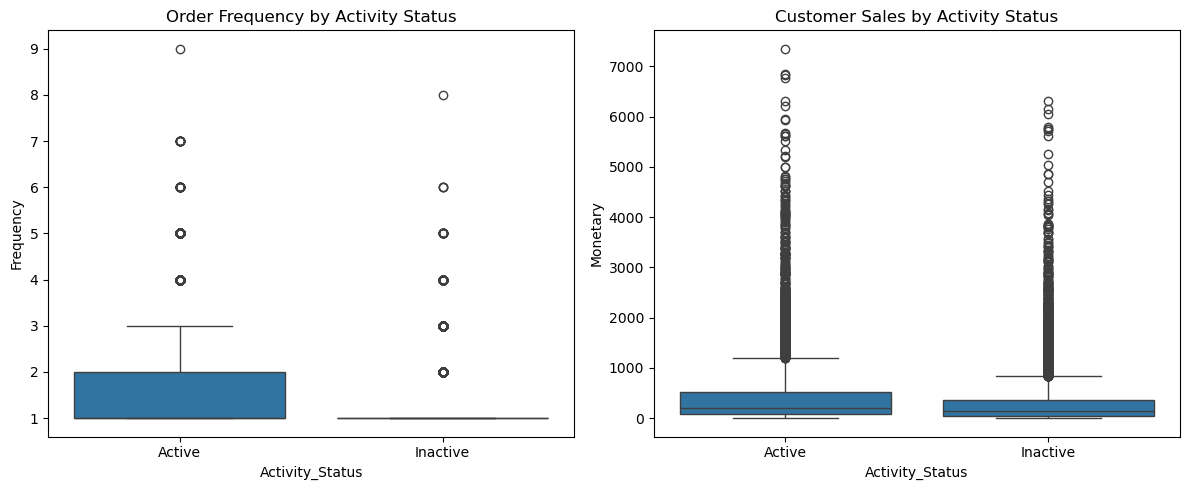

In [7]:


metrics = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Total_Profit",
    "Avg_Discount",
    "Average_Order_Value"
]

activity_summary = customer_df.groupby("Activity_Status")[metrics].mean().round(2)

print("===== ACTIVE VS INACTIVE CUSTOMER SUMMARY =====")
print(activity_summary.to_string())

print("\n===== CUSTOMER COUNTS =====")
print(customer_df["Activity_Status"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=customer_df,
    x="Activity_Status",
    y="Frequency",
    ax=axes[0]
)
axes[0].set_title("Order Frequency by Activity Status")

sns.boxplot(
    data=customer_df,
    x="Activity_Status",
    y="Monetary",
    ax=axes[1]
)
axes[1].set_title("Customer Sales by Activity Status")

plt.tight_layout()
plt.show()


===== CORRELATION MATRIX =====
          Quantity  Sales  Discount  Profit
Quantity     1.000  0.491     0.000   0.215
Sales        0.491  1.000     0.008   0.417
Discount     0.000  0.008     1.000  -0.317
Profit       0.215  0.417    -0.317   1.000


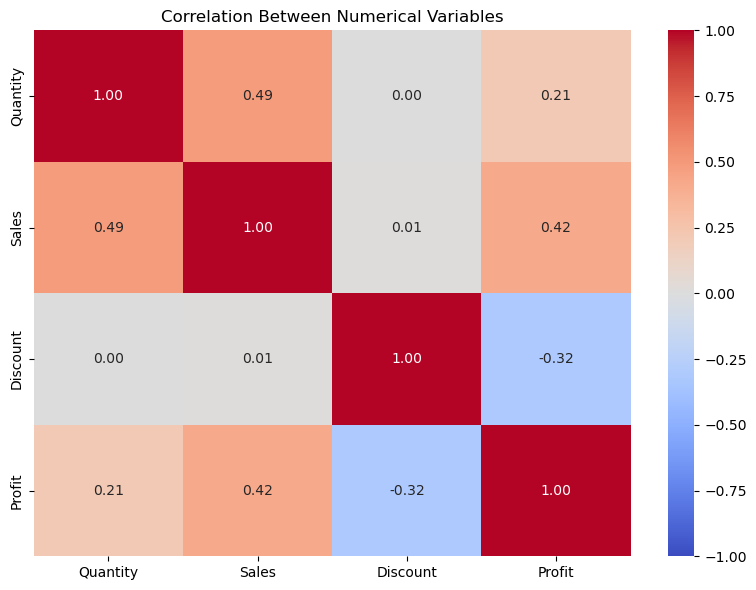

In [8]:

correlation_columns = [
    "Quantity",
    "Sales",
    "Discount",
    "Profit"
]

correlation_matrix = df[correlation_columns].corr()

print("===== CORRELATION MATRIX =====")
print(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()


In [10]:


customer_eda = customer_df.copy()

customer_eda["Recency_Group"] = pd.cut(
    customer_eda["Recency"],
    bins=[-1, 90, 180, 365, float("inf")],
    labels=["Recent (0-90 days)",
            "Cooling (91-180 days)",
            "At Risk (181-365 days)",
            "Inactive (>365 days)"]
)


customer_eda["Frequency_Group"] = pd.cut(
    customer_eda["Frequency"],
    bins=[0, 1, 2, float("inf")],
    labels=["One-time",
            "Two orders",
            "Frequent (3+ orders)"]
)

customer_eda["Spending_Group"] = pd.qcut(
    customer_eda["Monetary"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

print("===== RECENCY GROUPS =====")
print(customer_eda["Recency_Group"].value_counts().sort_index())

print("\n===== FREQUENCY GROUPS =====")
print(customer_eda["Frequency_Group"].value_counts().sort_index())

print("\n===== SPENDING GROUPS =====")
print(customer_eda["Spending_Group"].value_counts().sort_index())

print("\n===== SAMPLE ENGINEERED FEATURES =====")
print(
    customer_eda[
        ["Customer ID", "Recency", "Frequency", "Monetary",
         "Recency_Group", "Frequency_Group", "Spending_Group"]
    ].head(10).to_string(index=False)
)


===== RECENCY GROUPS =====
Recency_Group
Recent (0-90 days)        2814
Cooling (91-180 days)     2053
At Risk (181-365 days)    2780
Inactive (>365 days)      9768
Name: count, dtype: int64

===== FREQUENCY GROUPS =====
Frequency_Group
One-time                11979
Two orders               3467
Frequent (3+ orders)     1969
Name: count, dtype: int64

===== SPENDING GROUPS =====
Spending_Group
Low          4386
Medium       4340
High         4336
Very High    4353
Name: count, dtype: int64

===== SAMPLE ENGINEERED FEATURES =====
 Customer ID  Recency  Frequency  Monetary          Recency_Group      Frequency_Group Spending_Group
 AA-10315102      358          2       916 At Risk (181-365 days)           Two orders      Very High
 AA-10315120      959          1        63   Inactive (>365 days)             One-time            Low
 AA-10315139      149          4       599  Cooling (91-180 days) Frequent (3+ orders)      Very High
AA-103151402      184          2       228 At Risk (181-3

In [11]:

transaction_eda = df.copy()

transaction_eda["Order_Month"] = transaction_eda["Order Date"].dt.month
transaction_eda["Order_Quarter"] = (
    transaction_eda["Order Date"].dt.quarter
)
transaction_eda["Order_Year"] = transaction_eda["Order Date"].dt.year

transaction_eda["Profit_Margin_Pct"] = (
    transaction_eda["Profit"] / transaction_eda["Sales"] * 100
).round(2)

transaction_eda["Sales_Per_Unit"] = (
    transaction_eda["Sales"] / transaction_eda["Quantity"]
).round(2)

customer_eda.to_csv("week4_customer_features.csv", index=False)
transaction_eda.to_csv("week4_transaction_features.csv", index=False)

print("===== FINAL DATASET VALIDATION =====")

print("\nCustomer dataset shape:", customer_eda.shape)
print("Transaction dataset shape:", transaction_eda.shape)

print("\nCustomer dataset missing values:",
      customer_eda.isnull().sum().sum())

print("Transaction dataset missing values:",
      transaction_eda.isnull().sum().sum())

print("\nCustomer dataset duplicate rows:",
      customer_eda.duplicated().sum())

print("Transaction dataset duplicate rows:",
      transaction_eda.duplicated().sum())

print("\nCustomer engineered features:",
      ["Recency_Group", "Frequency_Group", "Spending_Group"])

print("Transaction engineered features:",
      ["Order_Month", "Order_Quarter", "Order_Year",
       "Profit_Margin_Pct", "Sales_Per_Unit"])

print("\nWeek 4 datasets saved successfully.")


===== FINAL DATASET VALIDATION =====

Customer dataset shape: (17415, 12)
Transaction dataset shape: (51290, 27)

Customer dataset missing values: 0
Transaction dataset missing values: 0

Customer dataset duplicate rows: 0
Transaction dataset duplicate rows: 0

Customer engineered features: ['Recency_Group', 'Frequency_Group', 'Spending_Group']
Transaction engineered features: ['Order_Month', 'Order_Quarter', 'Order_Year', 'Profit_Margin_Pct', 'Sales_Per_Unit']

Week 4 datasets saved successfully.
